# <center> Matrix factorization</center>

План:
- SVD разложение и специфика для рекомендательной системы
- Разновидности SVD: Compact SVD, Truncated SVD, Funk SVD, SVD++, Time SVD++.
- t-SNE визуализация

In [1]:
import warnings
warnings.filterwarnings("ignore")

from math import sqrt
import numpy as np
import pandas as pd
import pickle
import seaborn as sns
import scipy as sp
import scipy.sparse as scs
import matplotlib
import matplotlib.pyplot as plt
from numpy.linalg import svd
from sklearn.manifold import TSNE
from sklearn.metrics import r2_score
from sklearn.preprocessing import LabelEncoder
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.notebook import tqdm
from PIL import Image
from IPython.display import display
from ipywidgets import interact, widgets

%matplotlib inline

matplotlib.rcParams['figure.figsize'] = (12, 10)
np.set_printoptions(2, suppress=True)
plt.rcParams.update({'font.size': 14})

**Пояснение к импортам.**

- `numpy.linalg.svd` — «полное» (не усечённое и не разреженное) SVD-разложение; используем его в теоретических примерах ниже, где матрица целиком помещается в память.
- `scipy.sparse` (`scs`) — разреженные форматы (`coo_array`, `csr`) для матрицы интеракций: явное хранение только ненулевых оценок экономит память, когда пользователей и айтемов много, а оценок у каждого пользователя — единицы.
- `sklearn.manifold.TSNE` — нелинейное снижение размерности для визуализации эмбеддингов в 2D/3D (в отличие от SVD/PCA, старается сохранить **локальную** структуру соседства, а не глобальную дисперсию — поэтому хорош именно для картинки, но не для итогового представления признаков).
- `torch` / `torch.nn` / `torch.optim` — понадобятся ниже для Funk SVD: там матрицы факторов не раскладываются аналитически, а **обучаются** градиентным спуском как обычные embedding-слои нейросети.
- `ipywidgets` (`interact`, `widgets`) — интерактивный слайдер для визуального исследования, как меняется восстановленное изображение в зависимости от числа взятых компонент `k`.

### Что такое MF

**Матричная факторизация** (Matrix Factorization, MF) - это матричное разложение, которое является простой моделью латентных эмбеддингов.

Будем раскладывать исходную матрицу интеракций $A$ на несколько матриц (обычно 2 или 3), которые будут ее аппроксимировать при перемножении $PQ^T$.

Таким образом:

* Матрица интеракций $A \in R^{m \times n} $ <br> (далее в обозначениях также будет фигурировать как R - матрица рейтингов)
* Матрица эмбеддингов пользователей $P \in R^{m \times dim}$, где ряд $i$ - это эмбеддинг пользователя $i$. <br>
* Матрица эмбеддингов айтемов $Q \in R^{n \times dim}$, где ряд $j$ - это эмбеддинг айтема $j$.

Пара $(i, j)$ в $PQ^T$ - это скалярное произведение $<P_i, Q_j>$ эмбеддингов пользователя i и айтема j, которое должно быть близко к $A_{ij}$

<img src='../week3/images/MF.png' width=700>

$$ A ≈ (\tilde U \tilde \Sigma)^T \cdot \tilde V^T = P^T \cdot Q.$$

**Определение целевой функции для MF**

Одной из интуитивно понятных целевых функций для MF является квадрат расстояния. Для этого минимизируйте сумму квадратов ошибок по всем парам наблюдаемых записей:

$$min_{P \in R^{m\times d}, Q \in R^{n\times d}} \sum_{(i,j) \in obs} (A_{ij} - <P_i, Q_j>)^2$$

Вы можете решать эту квадратичную задачу с помощью сингулярного разложения матрицы (SVD).

## SVD

<img src='https://www.dataminingapps.com/wp-content/uploads/2020/02/svd2.png'>

$$ R = U \Sigma V^T$$



Сингулярные значения диагональной матрицы содержательно представляют собой меру важности каждого из скрытых факторов, которые используются для приближения исходной матрицы $A$. Чем больше сингулярное значение, тем больше вклад этого скрытого фактора в исходные данные. Сингулярные значения считаются как квадратные корни из собственных значений. В контексте рекомендательных систем, они позволяют определить, какие скрытые факторы (например, какие -то определяющие паттерны в данных по пользователям и айтемам) играют более важную роль при создании рекомендаций.

Когда мы собираем матрицу интеракций только по положительным парам, появляется проблема для SVD - сингулярное разложение не определено для неполнных матриц, а у нас матрица неполная.
Что делать?


Cделаем матрицу разрежененной (разреженная от неполной отличается тем, что неизвестные значения доопределены нулями), но при этом хранить и делать вычислительные операции мы все равно можем в sparse формате.

Сделаем сначала симуляцию такой матрицы:

In [110]:
A = np.zeros((20, 5))
non_zero_count = int(A.size * 0.2)
non_zero_indices = np.random.choice(A.size, non_zero_count, replace=False)
A.ravel()[non_zero_indices] = np.random.randint(0, 6, non_zero_count)
A

array([[1., 0., 0., 0., 4.],
       [0., 0., 1., 0., 0.],
       [0., 0., 3., 0., 1.],
       [0., 0., 0., 5., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 2., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 2., 0.],
       [0., 0., 1., 5., 0.],
       [0., 0., 0., 5., 0.],
       [0., 0., 0., 0., 0.],
       [3., 0., 0., 0., 0.],
       [4., 3., 0., 0., 0.],
       [0., 0., 0., 0., 4.],
       [0., 0., 0., 0., 0.]])

In [3]:
a = np.array([[1,2,3],[4,5,6],[10,20,30]])

x = np.array([0,0,2])
y = np.array([1,2,0])
vals = np.array([-1,-2,-3])

a[x,y] = vals

In [4]:
a

array([[ 1, -1, -2],
       [ 4,  5,  6],
       [-3, 20, 30]])

**Что здесь происходит.** Создаём матрицу `A` размера `[20 пользователей, 5 айтемов]`, полностью заполненную нулями, а затем случайно «включаем» 20% её ячеек, проставляя туда случайную оценку от 0 до 5. Получилась ситуация, типичная для рекомендательных систем: матрица **разреженная** (sparse) — большинство ячеек не заполнено, потому что пользователь физически не может оценить все айтемы. При этом мы **не** отличаем технически "нет оценки" от "оценка 0" — это и есть та проблема, о которой предупреждает markdown-ячейка выше: обычное SVD не умеет работать с *неполными* матрицами (где часть значений неизвестна), поэтому мы искусственно доопределяем пропуски нулями и дальше работаем с этой матрицей как с полностью заданной. Это упрощение — и именно оно объясняет, зачем позже понадобятся альтернативы вроде Funk SVD, которые оптимизируются только по *реально наблюдённым* парам.

In [111]:
U, s, V = svd(A)
U.shape, s.shape, V.shape

((20, 20), (5,), (5, 5))

**Пояснение к размерностям.** `numpy.linalg.svd` по умолчанию считает **полное** (full) SVD — `full_matrices=True`. Для матрицы `A` размера `m x n` (здесь `20 x 5`) это значит:

- `U` имеет размер `m x m` = `20 x 5` → на самом деле `(20, 20)` — квадратная ортогональная матрица;
- `s` — не матрица, а **одномерный вектор** длины `min(m, n) = 5` с сингулярными числами;
- `V` (в numpy это уже `V^T`, транспонированная) имеет размер `n x n` = `(5, 5)`.

Обратите внимание: `s` короче, чем стороны `U` и `V` — сингулярных чисел ровно `min(m, n)`, а сами матрицы `U`, `V` при полном SVD **квадратные** (чтобы быть ортонормированными базисами всего пространства, а не только той части, что участвует в разложении). Из-за этого несоответствия размеров матрицу сингулярных чисел `Σ` нельзя взять просто как `np.diag(s)` — её нужно "дополнить" нулевыми строками до формы, совместимой с `U` и `V` (это и делает следующая ячейка).

In [112]:
S = np.zeros(A.shape)
S[:len(s), :len(s)] = np.diag(s)
S

array([[9.13, 0.  , 0.  , 0.  , 0.  ],
       [0.  , 6.04, 0.  , 0.  , 0.  ],
       [0.  , 0.  , 5.41, 0.  , 0.  ],
       [0.  , 0.  , 0.  , 3.2 , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 1.64],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  ]])

Обратите внимание, что нижние нулевые строки нужны, чтобы составить ортонормированный базис (боковые матрицы  U и V образуют базис векторов в пространствах пользователей и айтемов соответственно. Базис - это набор векторов, который может быть использован для представления любого вектора в данном пространстве.)

Формально: `S` получает размер исходной матрицы `A`, то есть `(20, 5)` — **не квадратная**, а прямоугольная, с диагональным блоком `5x5` из сингулярных чисел в левом верхнем углу и нулями во всех остальных 15 строках. Только с такой формой умножение `U (20x20) @ S (20x5) @ V (5x5)` вообще корректно по правилам линейной алгебры и восстанавливает исходную матрицу `A` размера `(20, 5)`.

In [113]:
U @ S @ V

array([[ 1., -0.,  0.,  0.,  4.],
       [-0., -0.,  1., -0.,  0.],
       [-0., -0.,  3., -0.,  1.],
       [-0., -0., -0.,  5.,  0.],
       [ 0.,  0.,  0.,  0.,  0.],
       [-0., -0., -0.,  2.,  0.],
       [ 0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.],
       [-0., -0., -0.,  2.,  0.],
       [-0., -0.,  1.,  5.,  0.],
       [-0., -0., -0.,  5.,  0.],
       [ 0.,  0.,  0.,  0.,  0.],
       [ 3., -0.,  0.,  0.,  0.],
       [ 4.,  3., -0., -0., -0.],
       [-0., -0.,  0., -0.,  4.],
       [ 0.,  0.,  0.,  0.,  0.]])

In [114]:
np.allclose(A, U @ S @ V)

True

`np.allclose(A, U @ S @ V)` возвращает `True`: при **полном** (не усечённом) SVD произведение `U Σ V^T` восстанавливает исходную матрицу **точно** (с точностью до погрешности вычислений с плавающей точкой) — это не приближение, а тождественное разложение. Приближение появится только тогда, когда мы начнём сознательно отбрасывать часть сингулярных чисел (см. Truncated SVD ниже).

Давайте сначала повизуализируем, что значит выбор компонент из SVD на примере картинок и как это влияет на качество восстановления на практике:

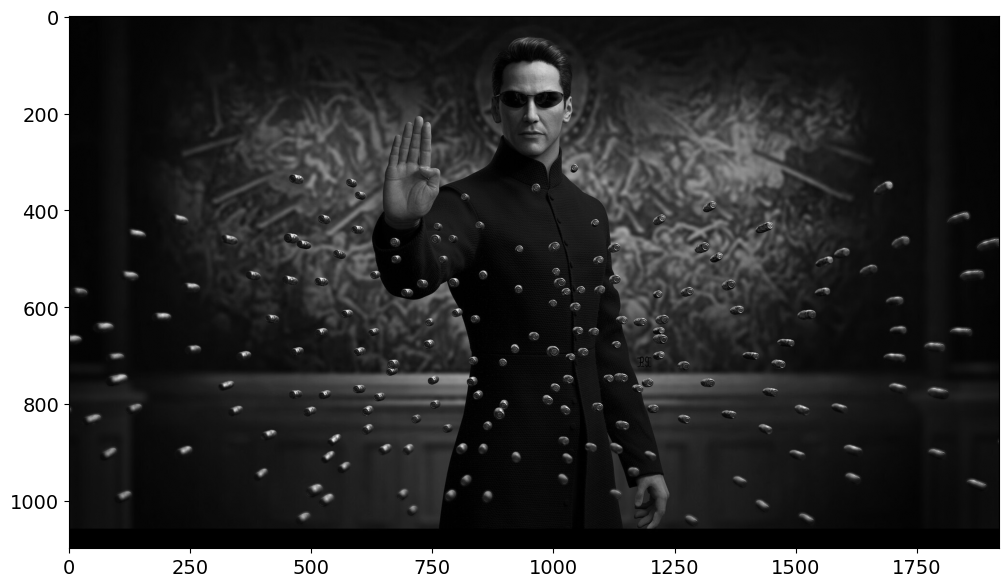

In [115]:
nice_pic = np.array(Image.open('/content/neo.png').convert('L'))
plt.imshow(nice_pic, cmap='gray');

Изображение в градациях серого — это тоже просто матрица: значение в ячейке `[i, j]` — это яркость пикселя (0 — чёрный, 255 — белый). Удобный учебный пример: результат SVD можно не просто оценивать по числам, а **увидеть глазами** — насколько сильно теряется качество картинки при отбрасывании компонент.

In [116]:
U, s, V = svd(nice_pic)
print((U.shape, s.shape, V.shape))

((1098, 1098), (1098,), (1920, 1920))


Изображение обычно намного крупнее нашей игрушечной матрицы `20x5` (здесь, судя по дальнейшему коду, что-то около `1098` в меньшей стороне) — значит, и сингулярных чисел, и потенциальных "скрытых факторов" для приближения будет намного больше.

In [117]:
S = np.zeros(nice_pic.shape)
S[:len(s), :len(s)] = np.diag(s)
print(S.shape)
S

(1098, 1920)


array([[55357.38,     0.  ,     0.  , ...,     0.  ,     0.  ,     0.  ],
       [    0.  , 12610.16,     0.  , ...,     0.  ,     0.  ,     0.  ],
       [    0.  ,     0.  , 10234.61, ...,     0.  ,     0.  ,     0.  ],
       ...,
       [    0.  ,     0.  ,     0.  , ...,     0.  ,     0.  ,     0.  ],
       [    0.  ,     0.  ,     0.  , ...,     0.  ,     0.  ,     0.  ],
       [    0.  ,     0.  ,     0.  , ...,     0.  ,     0.  ,     0.  ]])

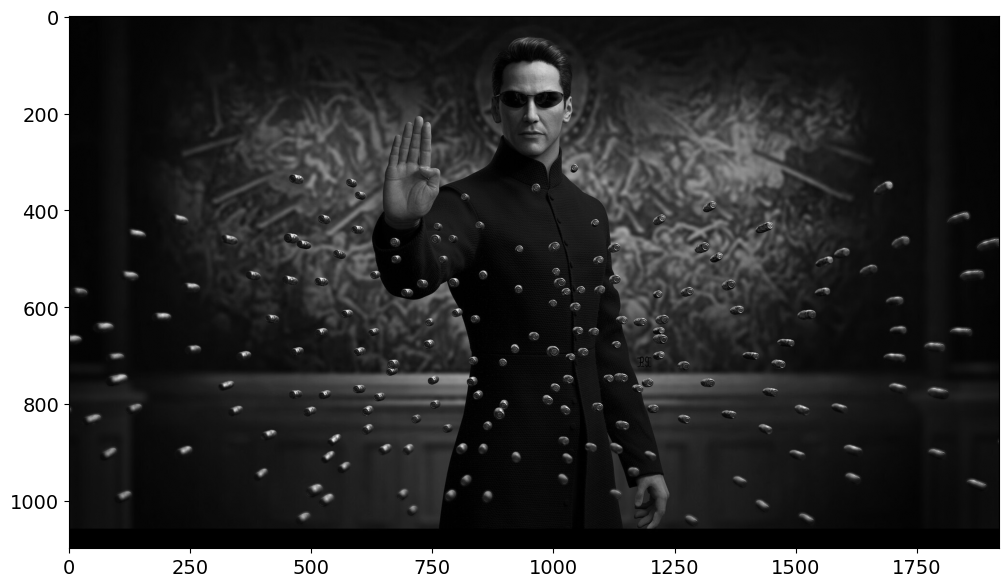

In [118]:
plt.imshow(U @ S @ V, cmap='gray');

При полном разложении картинка восстанавливается **без единой потери деталей** — визуально неотличима от оригинала, так как это точное (не усечённое) разложение, как и в примере с матрицей `A` выше.

In [119]:
def reshape_for_k(k: int, U, s, V):
    U_new = U[: , :k]
    S = np.zeros((U.shape[0], V.shape[1]))
    S[:len(s), :len(s)] = np.diag(s)
    S_new = S[: k, : k]
    V_new = V[: k, :]
    return U_new @ S_new @ V_new

reshape_for_k(1, U, s, V)

array([[2.  , 2.  , 2.04, ..., 2.29, 2.23, 2.11],
       [2.  , 2.01, 2.04, ..., 2.29, 2.23, 2.12],
       [2.01, 2.01, 2.05, ..., 2.29, 2.24, 2.12],
       ...,
       [0.  , 0.  , 0.  , ..., 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , ..., 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , ..., 0.  , 0.  , 0.  ]])

**Что делает `reshape_for_k`.** Это и есть **Truncated SVD** руками: вместо того чтобы использовать все `min(m, n)` сингулярных чисел, оставляем только первые `k` (они же — самые крупные, так как `svd` возвращает их отсортированными по убыванию):

- `U_new` — первые `k` столбцов `U` (по одному "скрытому направлению" на столбец);
- `S_new` — верхний левый блок `k x k` диагонали сингулярных чисел;
- `V_new` — первые `k` строк `V^T`.

Их произведение `U_new @ S_new @ V_new` даёт матрицу того же размера, что исходная, но теперь это уже **приближение ранга `k`** — согласно теореме Эккарта-Янга, это ещё и **наилучшее** возможное приближение ранга `k` по норме Фробениуса среди всех матриц такого ранга. При `k=1` картинка станет сильно размытой (используется только самое крупное "обобщённое" направление вариации яркости), а чем больше `k` — тем точнее будет восстановление, вплоть до полного совпадения при `k = rank(A)`.

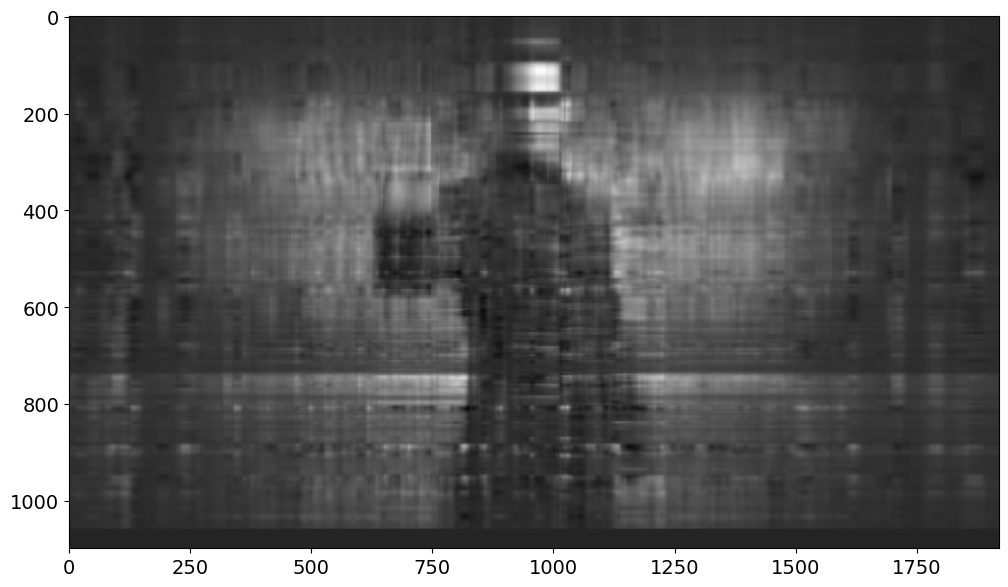

In [120]:
plt.imshow(reshape_for_k(9, U, s, V), cmap='gray');

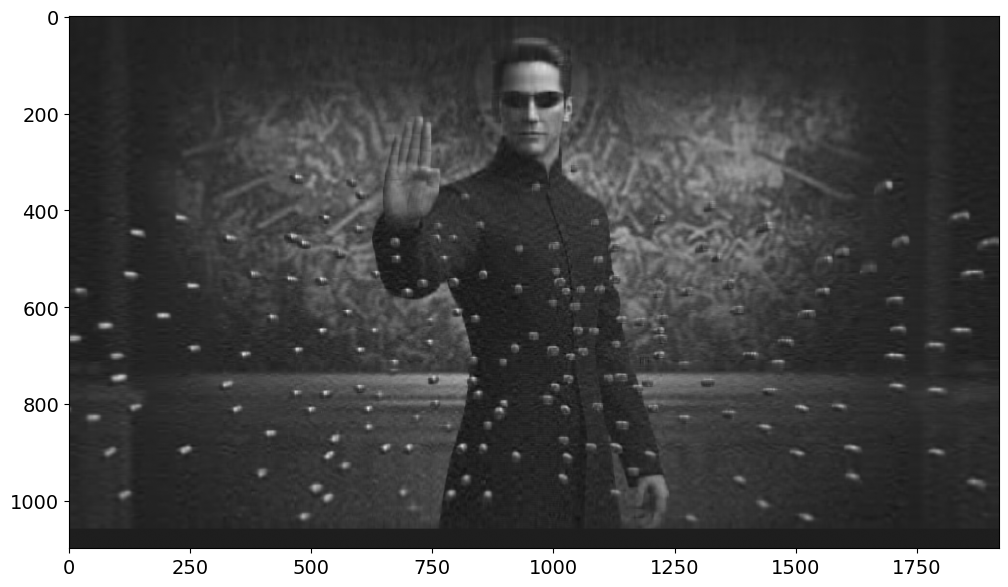

In [121]:
plt.imshow(reshape_for_k(69, U, s, V), cmap='gray');

## Hands-on рекомендательной системы на MF

Попробуем применить SVD на табличных данных для задачи рекомендации. Возьмем датасет из пользователей и фильмов.

In [122]:
ratings = pd.read_csv('/content/movies_ratings.csv')
ratings

,userId,movieId,rating,timestamp,title
0,1,31,2.5,1260759144,Dangerous Minds
1,7,31,3.0,851868750,Dangerous Minds
2,31,31,4.0,1273541953,Dangerous Minds
3,32,31,4.0,834828440,Dangerous Minds
4,36,31,3.0,847057202,Dangerous Minds
...,...,...,...,...,...
99845,664,64997,2.5,1343761859,H.G. Wells' War of the Worlds
99846,664,72380,3.5,1344435977,The Box
99847,665,129,3.0,995232528,Pie in the Sky
99848,665,4736,1.0,1010197684,Summer Catch


Загружаем таблицу `(userId, movieId, rating, ...)` — стандартный длинный (long) формат данных о рейтингах, из которого дальше будем собирать матрицу интеракций (аналогично домашнему заданию по ДЗ2).

In [123]:
num_users, num_movies = ratings.userId.nunique(), ratings.movieId.nunique()
num_users, num_movies

(671, 9025)

Число уникальных пользователей и фильмов — это и есть будущие размеры матрицы интеракций `R` (`num_users x num_movies`), которую предстоит разложить.

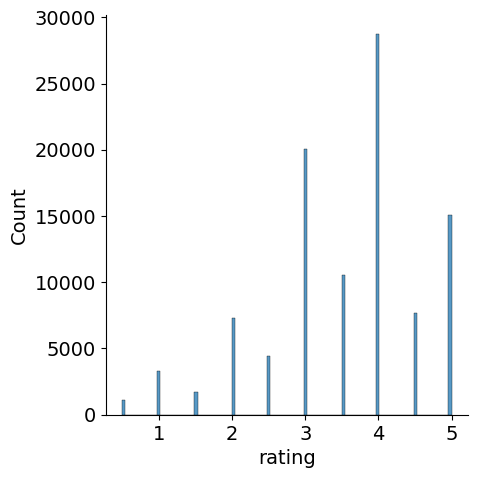

In [124]:
sns.displot(ratings.rating);

Распределение самих оценок (`rating`). На большинстве датасетов вроде MovieLens оно смещено в сторону высоких значений (люди чаще оценивают то, что им понравилось, и реже дооценивают то, что не понравилось / бросили смотреть) — это важно помнить: модель, которая просто восстанавливает такую матрицу как есть, будет по умолчанию оптимистична в своих предсказаниях.

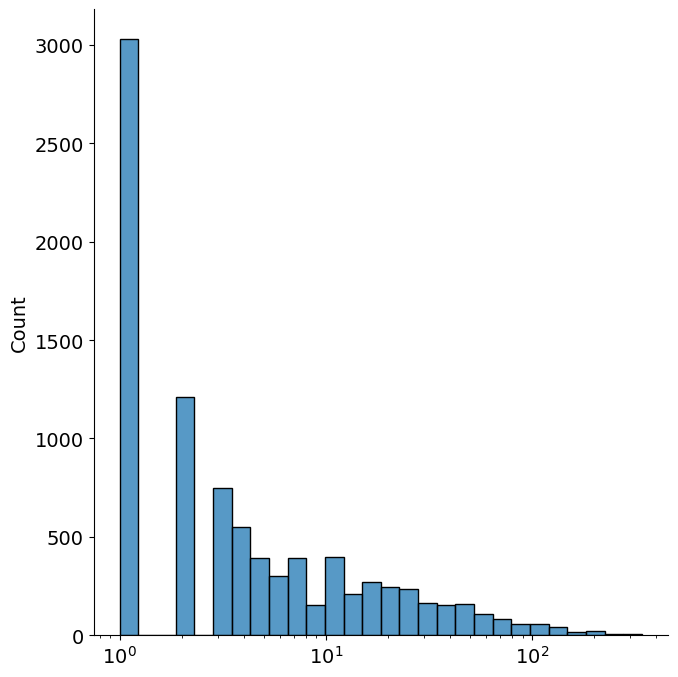

In [125]:
sns.displot(ratings.groupby('movieId').size(), log_scale=True, height=7);

Распределение числа оценок **на фильм**, в логарифмической шкале — классический "длинный хвост" (long tail): небольшое число очень популярных фильмов собирают огромную долю всех оценок, а у большинства фильмов оценок единицы. Это и есть та самая item popularity bias, о которой говорится в тексте markdown-ячейки 45 ниже — без поправки на неё модель будет систематически продвигать популярные айтемы.

Разделим выборку на обучение и тест следующим образом: для каждого пользователя в тестовую выборку попадут 10 его последних оценок.

**Пояснение к сплиту.** Это **temporal leave-last-k-out split**: для каждого пользователя откладываем в тест не случайные, а именно **последние по времени** `k=10` оценок, а всё, что было раньше — в трейн. Так тестовая выборка честно имитирует реальный сценарий использования (предсказываем будущее по прошлому, а не наоборот) — в отличие от случайного сплита, здесь не может быть "утечки из будущего" в обучение.

**Важное неявное допущение:** такой срез (`user_data[:-num_test_samples]` / `user_data[-num_test_samples:]`) по построению корректен, только если строки внутри `user_data` уже отсортированы по времени. Если это не гарантировано заранее (например, датафрейм не отсортирован по `timestamp`), нужно сначала явно сделать `user_data.sort_values('timestamp')`, иначе в "тест" попадут произвольные, а не последние оценки.

In [126]:
train_ratings, test_ratings = [], []
num_test_samples = 10

for userId, user_data in ratings.groupby('userId'):
    train_ratings += [user_data[:-num_test_samples]]
    test_ratings += [user_data[-num_test_samples:]]

train_ratings = pd.concat(train_ratings)
test_ratings = pd.concat(test_ratings)
train_ratings.shape, test_ratings.shape

((93140, 5), (6710, 5))

In [127]:
user_encoder, item_encoder = LabelEncoder(), LabelEncoder()
train_ratings['userId'] = user_encoder.fit_transform(train_ratings['userId'])
train_ratings['movieId'] = item_encoder.fit_transform(train_ratings['movieId'])


user_ids = np.array(train_ratings['userId'].tolist())
movie_ids = np.array(train_ratings['movieId'].tolist())
user_ratings = np.array(train_ratings["rating"].tolist())
print ('num of users:',train_ratings['userId'].nunique())
print ('num of movies:',train_ratings['movieId'].nunique())

num of users: 671
num of movies: 8044


`LabelEncoder` перекодирует произвольные `userId`/`movieId` в плотные индексы `0, 1, 2, ...` — это нужно, чтобы дальше строить матрицу/тензор индексами, а не реальными (разреженными и произвольно большими) идентификаторами. Обратите внимание: кодировщики обучены (`fit_transform`) **только на трейне** — значит, если в тесте встретится пользователь или фильм, которых не было в трейне, для них `transform` упадёт с ошибкой.

In [128]:
R = scs.coo_array((train_ratings.rating, (train_ratings.userId, train_ratings.movieId)),
                       shape=(num_users, num_movies)).tocsr()
matrix = R.toarray()

Собираем разреженную матрицу интеракций: `coo_array` принимает тройку `(данные, (строки, столбцы))` — ровно то, что у нас есть в `train_ratings` — и сразу конвертируем в `csr` (Compressed Sparse Row), формат, удобный для быстрых построчных операций и умножений матриц. `matrix = R.toarray()` разворачивает её обратно в плотный `np.ndarray`, потому что дальше используется `numpy.linalg.svd`, которая **не умеет** работать с разреженными матрицами напрямую (для этого в ДЗ2 использовалась отдельная функция `scipy.sparse.linalg.svds`).

In [129]:
U, s, V = svd(matrix)
U.shape, s.shape, V.shape

((671, 671), (671,), (9025, 9025))

In [130]:
S = np.zeros(matrix.shape)
S[:len(s), :len(s)] = np.diag(s)
print(S.shape)
S

(671, 9025)


array([[514.18,   0.  ,   0.  , ...,   0.  ,   0.  ,   0.  ],
       [  0.  , 241.23,   0.  , ...,   0.  ,   0.  ,   0.  ],
       [  0.  ,   0.  , 198.9 , ...,   0.  ,   0.  ,   0.  ],
       ...,
       [  0.  ,   0.  ,   0.  , ...,   0.  ,   0.  ,   0.  ],
       [  0.  ,   0.  ,   0.  , ...,   0.  ,   0.  ,   0.  ],
       [  0.  ,   0.  ,   0.  , ...,   0.  ,   0.  ,   0.  ]])

In [131]:
preds_matrix = U @ S @ V

In [132]:
preds_matrix

array([[-0.,  0., -0., ...,  0.,  0.,  0.],
       [-0., -0., -0., ...,  0.,  0.,  0.],
       [ 0., -0., -0., ...,  0.,  0.,  0.],
       ...,
       [-0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 4.,  0.,  0., ...,  0.,  0.,  0.],
       [ 5.,  0.,  0., ...,  0.,  0.,  0.]])

In [133]:
np.allclose(matrix, preds_matrix)

True

**Ключевой методологический момент.** Мы применили **полное** SVD к реальной матрице оценок, где пропуски ("нет оценки") заранее заполнены нулями — точно как в игрушечном примере из начала ноутбука. `np.allclose(matrix, preds_matrix)` здесь тоже должен дать `True`, потому что это снова точное (не усечённое) разложение. Но именно поэтому такое применение SVD "в лоб" плохо подходит для реальных рекомендаций: модель без остатка выучивает исходные нули как "эта пара пользователь-айтем действительно имеет рейтинг 0", а не как "мы просто не знаем оценку" — из-за этого предсказанные скор для невиденных айтемов будут смещены в сторону нуля. На практике эту проблему решают усечением ранга (Truncated SVD, дальше по ноутбуку) и/или переходом к моделям, которые оптимизируются только по наблюдённым парам (Funk SVD, iALS).

In [134]:
k = 20
df = pd.DataFrame(data=(zip(matrix[0, :], preds_matrix[0, :])),
                  columns=['init', 'preds']).sort_values(by='init', ascending=False)
df['preds'] = df['preds'].astype('float32')
df.sort_values(by='preds', ascending=False).head(k)

,init,preds
875,4.0,4.000000e+00
1024,3.5,3.500000e+00
805,3.0,3.000000e+00
781,3.0,3.000000e+00
30,2.5,2.500000e+00
1028,2.0,2.000000e+00
960,2.0,2.000000e+00
851,2.0,2.000000e+00
984,2.0,2.000000e+00
990,2.0,2.000000e+00


Для пользователя с индексом `0` сравниваем исходные оценки (`init`) с предсказанными после реконструкции (`preds`) и сортируем по убыванию предсказанного скора — получаем персональный топ-`k` рекомендаций.

Обратите внимание, что список рекомендаций выше - смешанный, у него в топе те айтемы, которые уже были в матрице интеракций пользователя. Когда нам нужно сделать только новые рекомендации - можем профильтровать.

In [135]:
df.sort_values(by='preds', ascending=False).head(k)[df.init == 0]

,init,preds
2262,0.0,3.141237e-14
96,0.0,2.488808e-14
31,0.0,2.353673e-14
860,0.0,2.325570e-14
580,0.0,2.152445e-14
1382,0.0,2.117403e-14
268,0.0,2.098322e-14
914,0.0,2.009504e-14
1229,0.0,1.949829e-14
249,0.0,1.892930e-14


Фильтруем `df.init == 0`, чтобы оставить только айтемы, с которыми пользователь ещё не взаимодействовал — иначе в топе рекомендаций окажутся фильмы, которые он и так уже оценил (что видно по предыдущему выводу).

**Небольшой методологический нюанс этого кода:** фильтр `[df.init == 0]` применяется **после** `.head(k)`, то есть сначала берутся первые `k=20` строк по убыванию `preds`, и только потом среди них отбираются невиденные. Если среди топ-20 окажется много уже просмотренных айтемов, после фильтрации останется **меньше** чем `k` рекомендаций. Чтобы гарантированно получить ровно `k` новых айтемов, правильнее сначала отфильтровать `df[df.init == 0]`, а `head(k)` сделать уже после — именно так реализовано `make_svd_recommendations` в решении ДЗ2 (маска `already_seen` ставится **до** выбора top-k).

### Другие типы SVD

$$ R = U \Sigma V^T$$

- **Full SVD**
$$ UU^T = U^TU = I_M$$
$$ VV^T = V^TV = I_N,$$

где $M$ x $M$ - размер матрицы $U$, $M$ x $N$ - размер матрицы $\Sigma$, $N$ x $N$ - размер матрицы $V$.

- **Compact SVD**

Берем матрицу $\Sigma$ по размеру ранга. Compact SVD не усекает данные и предоставляет точное разложение исходной матрицы.

$$ l = rank\{R\}$$
$$ U^TU = V^TV = I_l,$$

где $M$ x $l$ - размер матрицы $U$, $l$ x $l$ - размер матрицы $\Sigma$, $l$ x $N$ - размер матрицы $V$.

- **Truncated SVD**

Берем первые k компонент диагональной матрицы $\Sigma$.

$$ k << l = rank{R}$$
$$ U^TU = V^TV = I_k,$$

где $M$ x $k$ - размер матрицы $U$,  $k$ x $k$ - размер матрицы $\Sigma$, $k$ x $N$ - размер матрицы $V$.

**Важно** - обратите внимание, что матрица R теперь не равна разложению, она становится приближенной.

При формализации задачи разложения нужно соблюсти много условий. Например, что матрицы $U$ и $V$ должны быть ортогональны друг другу. На практике, пренебрегаем выполянется ли условие ортогональности, и просто решаем задачу приближения исходной матрицу перемножением двух новых, $U$ и $V$, и тогда нет единственности решения.
Обучение новых матриц чаще всего реализуется через SGD. Не без вытекающих проблем - накопление численных ошибок, дисбаланса матриц (одна растет, другая падает), но что можно нивелировать, например, через регуляризацию и кастомизацию штрафов. Например,если не хотим все айтемы штрафовать одинаково, т.к. есть item popularity bias, можно добавлять нормирование каждого айтема и домножить на свой собственный коэффициент.

Три термина из ячейки выше — это, по сути, три уровня усечения `k` в той самой функции `reshape_for_k`: **Full SVD** — исходный вызов `svd(A)` без обрезки; **Compact SVD** — `reshape_for_k(rank(A), ...)`, где мы обрезаем только те "лишние" размерности `U`/`V`, которые всё равно умножаются на нулевые сингулярные числа (реконструкция при этом остаётся **точной**); **Truncated SVD** — `reshape_for_k(k, ...)` при `k < rank(A)`, здесь реконструкция уже **приближённая**, и именно с этим уровнем мы работаем дальше, выбирая число латентных факторов для рекомендаций.

In [136]:
def reshape_for_k(k: int, U, s, V):
    U_new = U[: , :k]
    S = np.zeros((U.shape[0], V.shape[1]))
    S[:len(s), :len(s)] = np.diag(s)
    S_new = S[: k, : k]
    V_new = V[: k, :]
    return U_new @ S_new @ V_new

reshape_for_k(2, U, s, V)

array([[0.02, 0.01, 0.01, ..., 0.  , 0.  , 0.  ],
       [0.54, 0.21, 0.1 , ..., 0.  , 0.  , 0.  ],
       [0.63, 0.25, 0.08, ..., 0.  , 0.  , 0.  ],
       ...,
       [0.26, 0.1 , 0.04, ..., 0.  , 0.  , 0.  ],
       [0.46, 0.18, 0.06, ..., 0.  , 0.  , 0.  ],
       [1.8 , 0.72, 0.24, ..., 0.  , 0.  , 0.  ]])

Здесь `reshape_for_k` вызывается с `U, s, V` **из матрицы реальных рейтингов** (переменные были переопределены в ячейке `U, s, V = svd(matrix)` выше), а не из картинки — то есть мы применяем ту же самую логику truncated-приближения к матрице интеракций пользователь-фильм, получая low-rank аппроксимацию рейтингов рангом `k`.

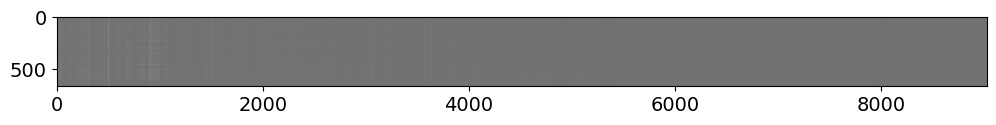

In [150]:
plt.imshow(reshape_for_k(5, U, s, V), cmap='gray');

При `k=50` реконструкция уже не идентична исходной матрице (в отличие от `k=rank`), но должна выделять основные, наиболее общие паттерны предпочтений — резкий переход от плотного изображения матрицы к разреженным исходным оценкам в этом виде визуально не так нагляден, как с картинкой, поэтому далее для подбора `k` используются количественные метрики (EVR, разреженность — см. следующие ячейки), а не визуальный осмотр.

In [138]:
@interact(k=widgets.IntSlider(min=1, max=1098))

def plot_figure(k):
    plt.title(f'k = {k}')
    new_img = reshape_for_k(k, U, s, V)
    plt.imshow(new_img, cmap='gray');

interactive(children=(IntSlider(value=1, description='k', max=1098, min=1), Output()), _dom_classes=('widget-i…

**Сколько компонент брать?**

Мы не хотим получить точно такую же матрицу, как была у нас в самом начале (overfit), но нам и не подойдет вариант с новой матрицей, где значения сильно разнятся с исходными (underfit).

Какие есть способы сравнить два набора данных? Можно построить простые графики метрики качества задачи восстановления исходных данных.

<img src='https://raw.githubusercontent.com/anamarina/RecSys_course/2021/week2/images/svd3.png' width=500>

В качестве метрики можем добавить коэффициент объясненной дисперсии и разреженность. Например, **Explained variance ratio (EVR)** и **Sparsity** — разреженность данных.
Как бы вы проинтерпретировали этот график?

<img src='https://raw.githubusercontent.com/anamarina/RecSys_course/main/week2/images/svd2.png' height=700 width=500>

Какие еще факторы важны при отборе количества главных компонент?

1. Качество самих рекомендаций (метрики ранжирования на оффлайн и онлайн) данных
2. Вычислительные ресурсы (RAM, жетский диск, требования к скорости расчетов и т.д.)

**t-SNE визуализация с Truncated SVD**

Иногда, когда делают честное SVD и ортогонализацию, компонентны можно распознать (популярность, жанр или что-то еще). На практике получить валидную интерпретацию тяжело, потому что это линейные комбинации разных характеристик и MF плохо интерпретируемы. Но можно пробовать отрисовывать главные компоненты (например, берем две компоненты и строим график с векторами айтемов на них) и делать визуальный анализ по кластерами примеров.  

Можно взять только часть компонент, например, первые 10 компонент.

In [139]:
R = pd.pivot_table(ratings, values='rating', index=['userId'],columns=['movieId'], fill_value=0).to_numpy()
print ('{0}x{1} user by user matrix'.format(*R.shape))

671x9025 user by user matrix


`pivot_table` строит **плотную** матрицу `[n_users, n_movies]` из длинного формата (альтернативный, более "pandas-идиоматичный" способ получить то же самое, что `df_to_matrix` из ДЗ2), заполняя пропуски нулём через `fill_value=0`.

In [140]:
train_user = R[:500, :1200]
test_user = R[500:, 1200:]

Здесь матрица режется на условные "train"/"test" куски по индексам строк и столбцов (`train_user`/`test_user`) — обратите внимание, что дальше по ноутбуку `test_user` **не используется**: код ниже (`TruncatedSVD`, `TSNE`) работает только с `train_user`. Судя по всему, это заготовка/остаток от другого эксперимента, не влияющая на итоговую визуализацию.

In [141]:
from sklearn.decomposition import TruncatedSVD

user_svd = TruncatedSVD(n_components=10)
user_features = user_svd.fit_transform(train_user)

print ("user_features.shape = {0}".format(user_features.shape))

user_features.shape = (500, 10)


`TruncatedSVD(n_components=10)` — готовая реализация усечённого SVD из `sklearn`, концептуально то же самое, что наш ручной `reshape_for_k`, но сразу возвращает `user_features` — компактные 10-мерные эмбеддинги **пользователей** (по одной строке матрицы `train_user` на пользователя, спроецированной в пространство первых 10 главных компонент).

In [142]:
tsne = TSNE(perplexity=5, n_components=3, init="pca", n_iter=1000)
plot_only = 15
coords_3d = tsne.fit_transform(user_features[:plot_only, :])

`TSNE` дополнительно сжимает уже 10-мерные эмбеддинги пользователей до 3 измерений специально для визуализации (в отличие от SVD, старается сохранить, у каких точек похожие *соседи*, а не общую дисперсию данных, поэтому расстояния на итоговом графике нельзя интерпретировать буквально как "похожесть" в исходном пространстве). `perplexity=5` — примерное ожидаемое число соседей для каждой точки, разумное значение для маленькой выборки (здесь визуализируем всего `plot_only=15` точек).

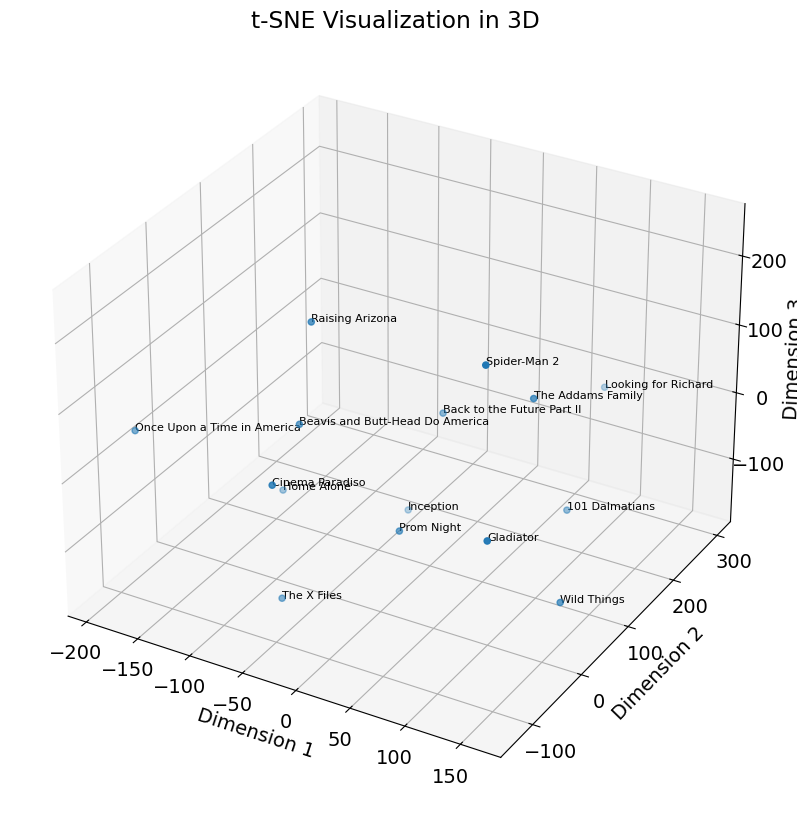

In [143]:
df_tsne_3d = pd.DataFrame(coords_3d, columns=['tsne_1', 'tsne_2', 'tsne_3'])

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

df = ratings.sample(frac=1).reset_index(drop=True)
ax.scatter(df_tsne_3d['tsne_1'], df_tsne_3d['tsne_2'], df_tsne_3d['tsne_3'])

for i, txt in enumerate(df['title'].iloc[:plot_only]):
    ax.text(df_tsne_3d['tsne_1'][i], df_tsne_3d['tsne_2'][i], df_tsne_3d['tsne_3'][i], '%s' % (txt), size=8, zorder=1)

ax.set_title('t-SNE Visualization in 3D')
ax.set_xlabel('Dimension 1')
ax.set_ylabel('Dimension 2')
ax.set_zlabel('Dimension 3')

plt.show();

- Правда ли, что у похожих айтемов будут похожие эмбеддинги?


Да, но смотря что вкладывать в похожесть.
Близость эмбеддингов по метрике расстояния (например, cosine similarity) интрепретируется не как похожие друг на друга фильмы по характеристикам (описание, жанр, режиссер и др.), а как часто совстречаемые фильмы у похожей по истории просмотров группы пользователей (которые им релевантны в порядке сортировки убывающей нормы векторов). Если угол между айтемами будет мал, то и предсказания у пользователей будут похожими за счет высокой частоты появления близкого фильма в их рекомендациях.

### Обучение матриц вместо разложения

$$r_{ui} = \hat r_{ui} = p^T_{u} q_i$$

$$ \Theta = \{p_u, q_i| u \in U, i \in I\}$$

$$\sum_{(u,i) \in D}(r_{ui} - \hat r_{ui})^2 + \lambda \sum_{\theta in \Theta}) ||\theta||^2 = \sum_{(u,i) \in D}(r_{ui} - p_u^T q_i)^2 + \lambda \sum_{u \in U} ||p_u||^2 + \lambda \sum_{i \in I} ||q_i||^2 $$

### Funk SVD

Funk SVD подход получил широкую [известность](https://sifter.org/simon/journal/20061211.html) после конкурса Netflix Prize в 2006 году, , хотя в индустрии подход не получил большой популярности, так как градиентный спуск сильно сложнее распараллелить, чем, например, ALS при не менее лучшем качестве.

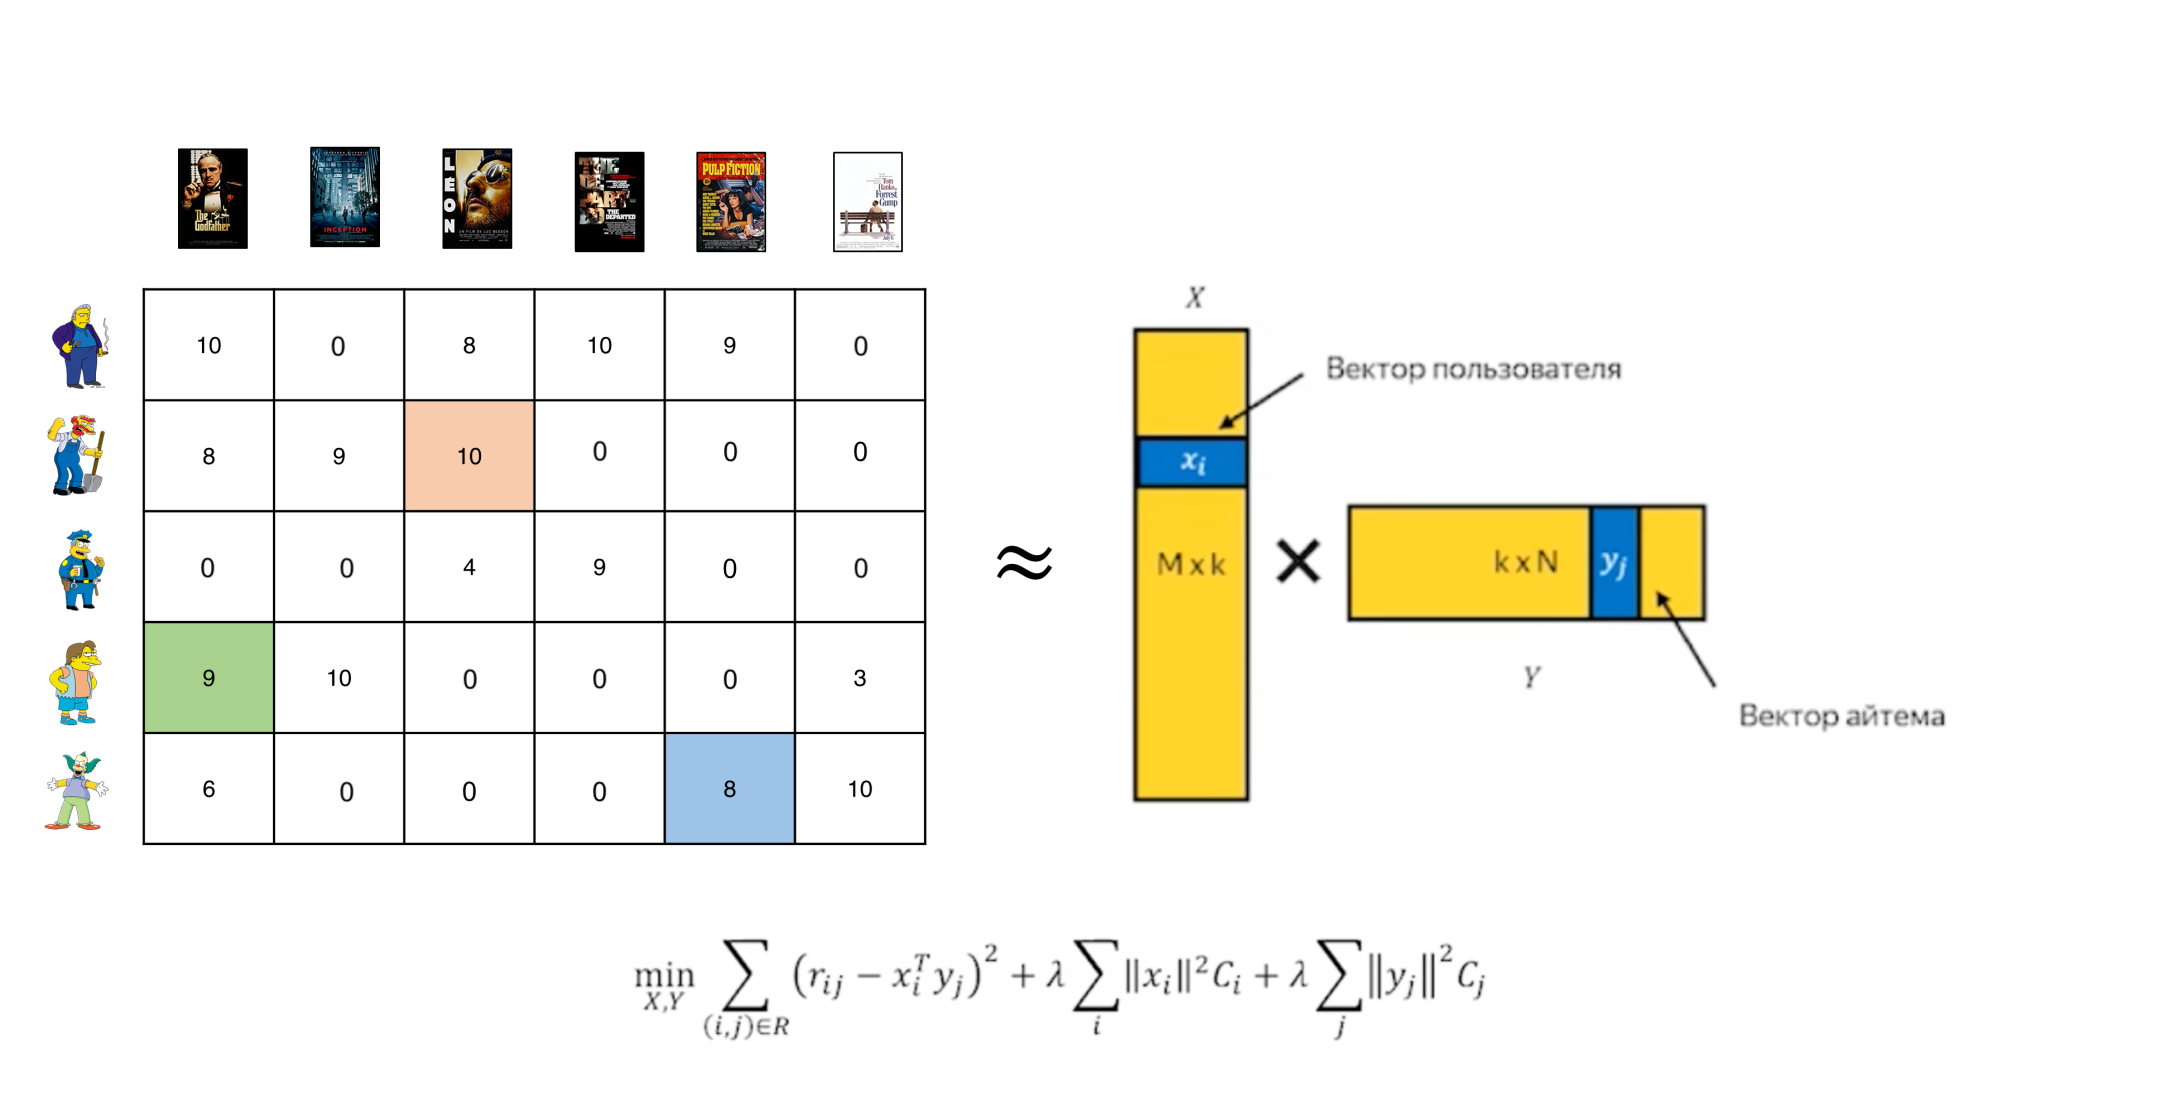

Помимо скалярного произведения, включает еще смещения по пользователю $b_u$ и айтему $b_i$. Тогда:

$$\hat r_{u,i} = \mu + b_u + b_i + q_{i}^{T}p_{u},$$

где $\mu$ - глобальное среднее по всем оценкам в данных. Тогда задача оптимизации сводится к:

$$ \sum(r_{u,i} - \hat r_{u,i}) ^ 2 +     \lambda(b_i^2 + b_u^2 + ||q_i||^2 + ||p_u||^2),$$

где $\lambda$ - параметр регуляризации.

Оптимизация через стохастический градиентный спуск:

$$b_u \leftarrow b_u + \gamma (e_{ui} - \lambda b_u)$$
$$b_i \leftarrow b_i + \gamma (e_{ui} - \lambda b_i)$$  
$$p_u \leftarrow p_u + \gamma (e_{ui} \cdot q_i - \lambda p_u)$$
$$q_i \leftarrow q_i + \gamma (e_{ui} \cdot p_u - \lambda q_i),$$

где $\gamma$ - это learning rate, <br>
$e_{ui} =  r_{ui} - \hat r_{u,i} = r_{u,i} - (\mu + b_u + b_i + q_{i}^{T}p_{u})$ ошибка алгоритма на паре $(u, i)$.

In [144]:
n_movie = train_ratings.movieId.nunique() # 8044
n_user = train_ratings.userId.nunique() # 671

embedding_size = 10
lr = 0.001
reg = 0.01

Задаём гиперпараметры будущей модели: `embedding_size=10` — размерность латентных векторов `p_u`, `q_i` (то самое `dim` из формул выше); `lr` — шаг обучения (`γ` в формулах SGD); `reg` — коэффициент L2-регуляризации (`λ`), который в PyTorch будет передан как `weight_decay` оптимизатору, а не реализован вручную.

In [145]:
n_movie, n_user

(8044, 671)

In [146]:
user_ids = torch.LongTensor(train_ratings['userId'].values)
movie_ids = torch.LongTensor(train_ratings['movieId'].values)
user_ratings = torch.FloatTensor(train_ratings['rating'].values) # kernel

Переносим обучающие данные в тензоры PyTorch: `LongTensor` для индексов (они пойдут в `nn.Embedding`, которая ожидает целочисленные индексы), `FloatTensor` для самих рейтингов (целевая переменная для MSE-лосса).

На пальцах:

$prediction = user\_embedding[userId] \cdot movie\_embedding[movieId] + user\_bias[userId] + movie\_bias[movieId] + global\_bias$


Функция потерь (L):

$||prediction - rating||^2 + \lambda (||user\_embedding||^2 + ||movie\_embedding||^2 + ||user\_bias||^2 + ||movie\_bias||^2)$

$\lambda$ - регуляризация с L2 loss.

In [147]:
class MatrixFactorization(nn.Module):

    def __init__(self, n_user, n_movie, embedding_size):
        super(MatrixFactorization, self).__init__()
        self.user_embedding = nn.Embedding(n_user, embedding_size)
        self.movie_embedding = nn.Embedding(n_movie, embedding_size)
        self.user_bias_embedding = nn.Embedding(n_user, 1)
        self.movie_bias_embedding = nn.Embedding(n_movie, 1)
        self.global_bias = nn.Parameter(torch.zeros(1))

    def forward(self, user, movie):
        u = self.user_embedding(user)
        m = self.movie_embedding(movie)
        u_bias = self.user_bias_embedding(user).squeeze()
        m_bias = self.movie_bias_embedding(movie).squeeze()
        predicted_rating = torch.sum(u * m, dim=1) + u_bias + m_bias + self.global_bias
        return predicted_rating

**Как устроена модель.** Четыре обучаемых embedding-таблицы:
- `user_embedding`, `movie_embedding` — латентные векторы `p_u`, `q_i` размерности `embedding_size`;
- `user_bias_embedding`, `movie_bias_embedding` — скалярные смещения `b_u`, `b_i` (embedding с выходной размерностью 1 на каждого пользователя/фильм);
- `global_bias` — единственный обучаемый скаляр `μ`, общий для всех пар.

`forward` в точности реализует формулу Funk SVD из ячейки выше: `μ + b_u + b_i + <p_u, q_i>`, где скалярное произведение считается как `torch.sum(u * m, dim=1)` — поэлементное умножение двух векторов эмбеддингов с последующим суммированием по признакам, что и есть определение dot product для батча векторов. `.squeeze()` у смещений убирает лишнюю размерность `[batch, 1] -> [batch]`, чтобы форма совпадала с формой скалярного произведения при сложении.

In [148]:
model = MatrixFactorization(n_user, n_movie, embedding_size)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=reg)

`nn.MSELoss()` реализует первое слагаемое из целевой функции — $\sum (r_{ui} - \hat r_{ui})^2$ (с точностью до усреднения по батчу вместо суммы). Второе слагаемое — регуляризация $\lambda(\|p_u\|^2 + \|q_i\|^2 + b_u^2 + b_i^2)$ — явно в коде не выписано: вместо этого используется `weight_decay=reg` у оптимизатора `Adam`, что математически эквивалентно L2-регуляризации по **всем** параметрам модели сразу (включая смещения) с одним и тем же коэффициентом `λ` — то есть чуть проще, чем в общем случае, где к разным группам параметров иногда применяют разные `λ`.

In [149]:
batch_size = 16
n_epoch = 3

for epoch in range(n_epoch):
    for start in range(0, len(user_ratings) - batch_size, batch_size):
        end = start + batch_size
        user_batch = user_ids[start:end]
        movie_batch = movie_ids[start:end]
        rating_batch = user_ratings[start:end]

        optimizer.zero_grad()
        outputs = model(user_batch, movie_batch)
        loss = criterion(outputs, rating_batch)
        loss.backward()
        optimizer.step()

    print("RMSE", torch.sqrt(loss).item())

movie_embeddings = model.movie_embedding.weight.detach().numpy()

RMSE 0.7355846762657166
RMSE 0.78140789270401
RMSE 0.7879213690757751


**Цикл обучения.** Классический мини-batch SGD (здесь конкретно — Adam, адаптивная версия SGD): данные не перемешиваются между эпохами (`shuffle` не делается — батчи каждую эпоху идут в одном и том же порядке, что теоретически может немного замедлять сходимость по сравнению со случайным перемешиванием, но не критично для демонстрации), по каждому батчу считается прямой проход (`forward`), ошибка (`MSELoss`), градиенты (`backward`) и обновление весов (`optimizer.step()`). После цикла из `model.movie_embedding.weight` можно достать обученные латентные векторы фильмов `q_i` — их, например, можно так же прогнать через t-SNE, как эмбеддинги из TruncatedSVD выше, только на этот раз подписи названиями фильмов будут иметь смысл, так как это действительно эмбеддинги айтемов.

Печатаемая метрика — это `RMSE` (квадратный корень из MSE) **только на последнем батче эпохи**, а не усреднённый по всей эпохе loss — реальная динамика обучения по всей обучающей выборке может быть чуть более гладкой, чем видно по этим точечным значениям.

### SVD++

[Factorization Meets the Neighborhood](https://www.cs.rochester.edu/twiki/pub/Main/HarpSeminar/Factorization_Meets_the_Neighborhood-_a_Multifaceted_Collaborative_Filtering_Model.pdf) - оригинальная статья предложенного алгоритма, где предлагается использовать хронологический порядок истории взаимодействий.

Обычно рассматривается только множество айтемов с явным отликом, $R(u)$, но чаще всего у нас имеются неявные данные.
Метод SVD++ можем учитывать множество айтемов с неявным откликом, $N(u)$:


$\hat{r}_{ui} =\mu + b_u + b_i + q^T_i \left( p_u + |N(u)|^{-1/2} \sum_{j \in N(u)} y_j \right) ,$



$\Theta = \{ \mu, b_u, b_i, p_u, q_i, y_i| u \in U, i \in I\} .$


Множество $N(u)$ можно заменить на $R(u)$, т.к. всегда выполняется $R(u) \subset N(u)$, и считать как item-item рекомендации.

### Time SVD++

Часто в истории взаимодействий пользователей существует информация о времени (например, в формате timestamp или какой-то даты, когда взаимодействие произошло). Как это использовать?

Автор статьи [Collaborative Filtering with Temporal Dynamics](http://citeseerx.ist.psu.edu/viewdoc/download?doi=10.1.1.379.1951&rep=rep1&type=pdf) из Yahoo предложил добавить зависимость от времени в модель SVD++, поскольку предпочтения пользователей динамично меняются, также как и смещения по юзерам и айтемам:


$\hat{r}_{ui}(t) =\mu + b_u(t) + b_i(t) + q^T_i \left( p_u(t) + |R(u)|^{-1/2} \sum_{j \in R(u)} y_j \right) .$


Для item bias:

$b_i(t) = b_i + b_{i, \text{Bin}(t)}$


Для user bias:

$b_i(t) = b_i + \alpha_u \cdot \text{dev}_u(t) + b_{u, t} \quad\quad\quad\quad \text{dev}_u(t) = \text{sign}(t - t_u) \cdot |t - t_u|^{\beta}$

Для эмбеддингов пользователей похожий трюк:

$p_u(t) = (p_{u1}(t), \dots, p_{uf}(t))^T$:
$p_{uk}(t) = p_{uk} + \alpha_{uk} \cdot \text{dev}_u(t) + p_{uk, t}. $



### Еще из лайфхаков про матричное разложение просто на примере приближенного подсчета SVD

Есть интересное свойство с использованием ортогональности.

$$ R = U\Sigma V^T $$

Если хотим рассмотреть только одну из ортогональных матриц, например, U, можем сделать следующее:

$$ R = U(\Sigma V^T) = U \tilde V ^T ,$$

где $\Sigma V^T$ дает нам новую матрицу, которая является проекцией матрицы R в пространство, описываемое матрицей U.
Таком образом, рассматриваем $\tilde V ^T$ как проекцию R в новое пространство, которое состоит только из левых сингулярных векторов U.

Матрицу V можно рассматреть по аналогии:

$$ R = (U\Sigma) V^T = \tilde U  V ^T.$$

На практике, когда это полезно - допустим, у нас непропорционально много пользователей или продуктов, можно хранить только матрицу по меньшей размерности.

<ins>Проверочные вопросы на понимание:</ins>

*  1. В чем может быть практическая польза хранить не исходную матрицу, а две/три новые матрицы?

*Помним, что обычно dim << n и dim << m, таким образом, на практике нам дешевле хранить в памяти две более компактные матрицы, чем исходную*

*  2. Что важнее для MF - абсолютное значение оценки или порядок между оценками айтемов?

* 3. В чем будут недостатки максимально точной аппроксимации исходной матрицы для рекомендательных систем (т.е. один к одному воспроизвести значения исходной материцы интеракций)?
     
* 4. Как проинтерпретировать матрицы U, S, V с точки зрения юзеров и айтемов?

* 5. Как получить рекомендации для i-го пользователя после разложения матрицы интеракций?

*  6. Считают ли матричные фаткоризации похожесть пользователей или айтемов напрямую?

* 7.  Можно ли проинтпретировать выученные характеристики и латентные векторы?

* 8. Правда ли, что из-за большого количества пропусков в матрице полученное SVD решение будет слишком шумным, и его придется каждый раз рассчитывать заново при добавлении новых пользователей или айтемов?
